# Experiment 4 — Tactical deconfliction with a fixed obstacle

This experiment repeats the fixed-obstacle scenario using only tactical deconfliction. Strategic deconfliction is disabled, so the original conflicting plan is initially approved. During execution, predicted tracks allow the Tactical Deconfliction Module to detect the obstacle and issue a vertical flight-plan update.

In [1]:
from pathlib import Path

from IPython.display import Image, display

from musas.airspace import Airspace, Cylinder3D, Obstacle
from musas.algorithms import (
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    MinimumSeparationTacticalConflictPrediction,
    VerticalManeuverDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    calculate_metrics,
    plot_dataset,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp4"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Scenario configuration

The original plan crosses the center of a cylindrical obstacle at `t = 15 s`. The tracking horizon is six seconds, so the tactical conflict becomes visible only after the UAV is already active.

In [2]:
SIMULATION_END = 42.0
ORIGINAL_CONFLICT_TIME = 15.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0

def create_flight_plan():
    return FlightPlan([
        Waypoint(-100.0, 0.0, 100.0, 0.0),
        Waypoint(100.0, 0.0, 100.0, 30.0),
    ])

def create_airspace():
    obstacle = Obstacle(
        obstacle_id="central-obstacle",
        name="Central obstacle",
        geometry=Cylinder3D(
            center_x=0.0,
            center_y=0.0,
            radius=20.0,
            minimum_z=90.0,
            maximum_z=110.0,
        ),
    )
    return Airspace(obstacles={obstacle.obstacle_id: obstacle})

## Run the baseline and tactical-deconfliction cases

Both cases use the same tracking algorithm and have strategic deconfliction disabled. Only the second case injects the tactical conflict-prediction and deconfliction algorithms.

In [3]:
CASES = {
    "without_td": "Without tactical deconfliction",
    "with_td": "With tactical deconfliction",
}

def run_case(case_name):
    dataset_path = DATASET_DIRECTORY / f"{case_name}.sqlite"
    tactical_arguments = {}

    if case_name == "with_td":
        tactical_arguments = {
            "tactical_conflict_prediction_algorithm": (
                MinimumSeparationTacticalConflictPrediction(
                    minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
                    maximum_time_difference=0.25,
                )
            ),
            "tactical_deconfliction_algorithm": (
                VerticalManeuverDeconfliction(
                    altitude_offset=30.0,
                    airspace_clearance=10.0,
                    minimum_maneuver_duration=4.0,
                    cooldown=20.0,
                )
            ),
        }

    simulation = Simulation(
        airspace=create_airspace(),
        tracking_algorithm=FlightPlanAwareTracking(),
        report_interval=0.5,
        history_window=6,
        prediction_horizon=12,
        prediction_step=0.5,
        flight_update_interval=0.1,
        trajectory_record_interval=0.1,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "tactical_deconfliction_obstacle",
            "case": case_name,
        },
        overwrite_dataset=True,
        **tactical_arguments,
    )
    simulation.add_uav(
        name="UAV 1",
        flight_plan=create_flight_plan(),
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=100.0,
            velocity_time_constant=0.0,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=15.0,
        ),
        waypoint_acceptance_radius=1.0,
    )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {case_name: run_case(case_name) for case_name in CASES}
dataset_paths

{'without_td': PosixPath('outputs/output_exp4/datasets/without_td.sqlite'),
 'with_td': PosixPath('outputs/output_exp4/datasets/with_td.sqlite')}

## Metrics

A successful tactical intervention should produce at least one detected tactical conflict and plan update while preventing an obstacle violation. The tactical-conflict metric counts detections across prediction cycles, so one physical encounter may be detected more than once.

In [4]:
print(
    f"{'Case':<36} {'tactical conflicts':>19} "
    f"{'interventions':>14} {'updates':>9} {'violations':>11} "
    f"{'real dist.':>12} {'real time':>10}"
)
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
    values = metrics["per_uav"]["UAV 1"]
    real_time = values["actual_time"]
    real_time_text = "not completed" if real_time is None else f"{real_time:.1f}"
    print(
        f"{CASES[case_name]:<36} "
        f"{metrics['detected_tactical_conflicts']:19d} "
        f"{metrics['tactical_interventions']:14d} "
        f"{values['updates']:9d} "
        f"{metrics['obstacle_violations']:11d} "
        f"{values['actual_distance']:12.2f} "
        f"{real_time_text:>10}"
    )

Case                                  tactical conflicts  interventions   updates  violations   real dist.  real time
Without tactical deconfliction                         0              0         0           1       198.66       29.9
With tactical deconfliction                            1              1         1           0       205.65       29.9


## Conflict-time figures

The figures use `plot_dataset()` in 3D and include the most recent predicted track available at the original conflict time.

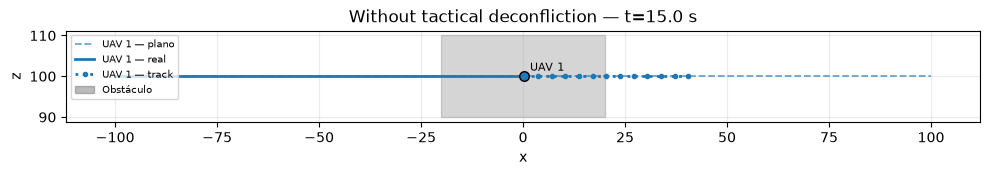

Saved: outputs/output_exp4/without_td.png


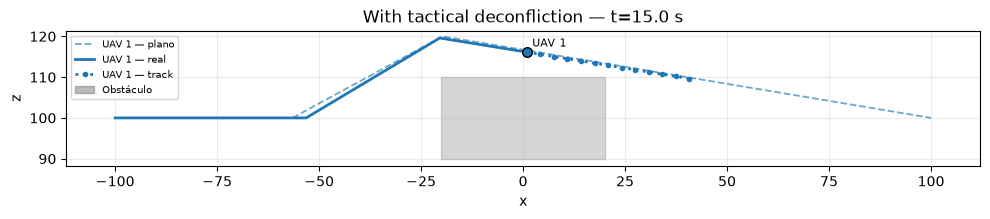

Saved: outputs/output_exp4/with_td.png


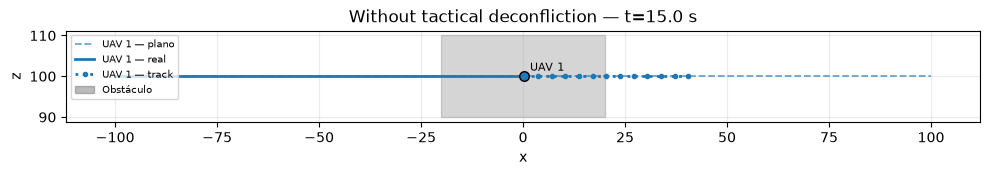

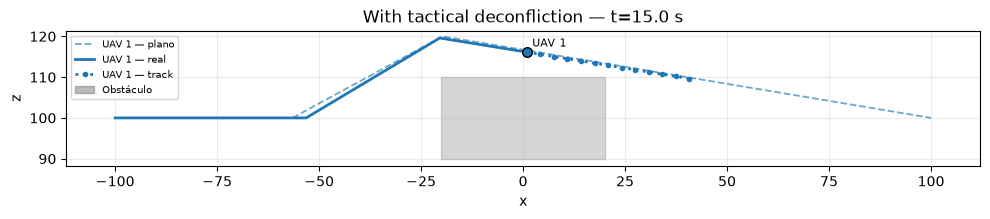

In [5]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV 1",),
        view="xz",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=True,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=True,
        frame_step=0.5,
        figure_size=(10.0, 7.0),
        title=CASES[case_name],
    )

for case_name, dataset_path in dataset_paths.items():
    figure_path = OUTPUT_DIRECTORY / f"{case_name}.png"
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        timestamp=ORIGINAL_CONFLICT_TIME,
        output_path=figure_path,
    )
    display(figure)
    print("Saved:", figure_path)

## Animations with tracking

The dotted lines are the most recent track predictions and are updated throughout each animation.

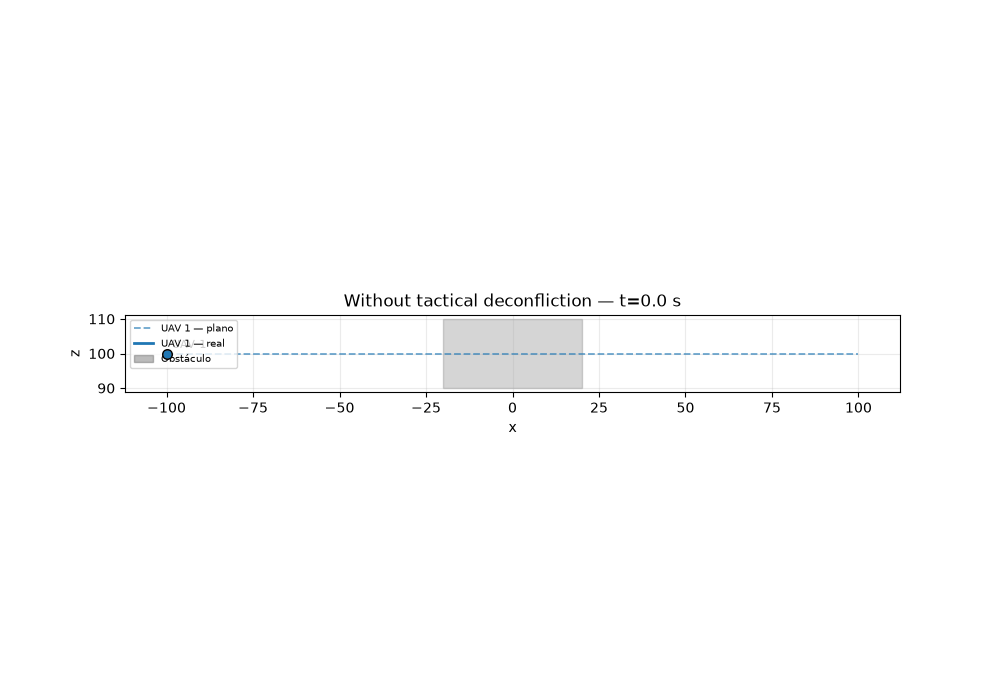

Saved: outputs/output_exp4/without_td.gif


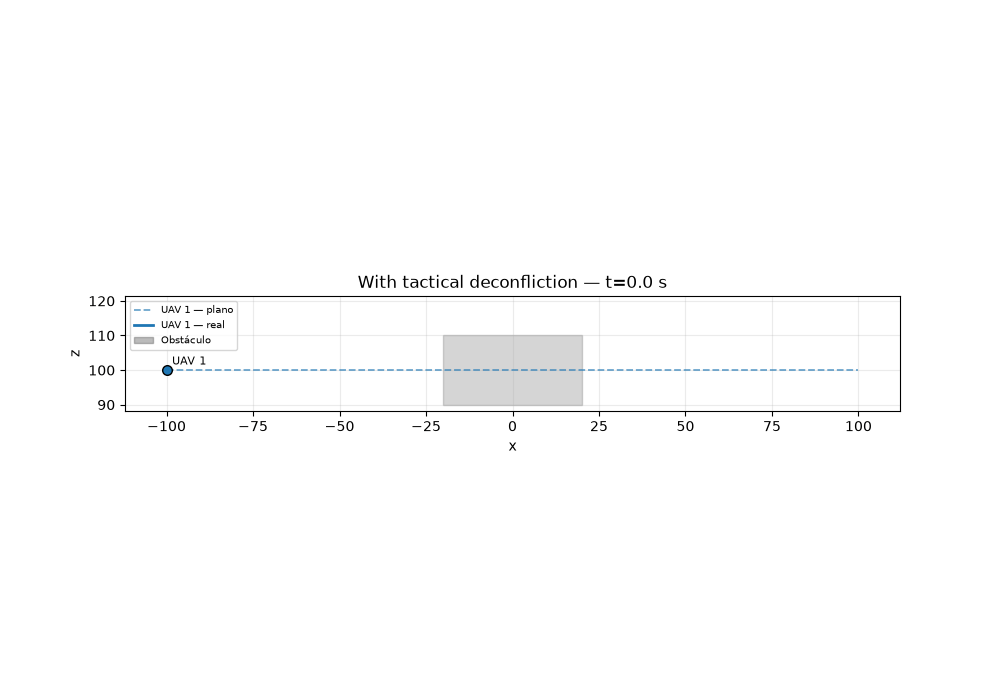

Saved: outputs/output_exp4/with_td.gif


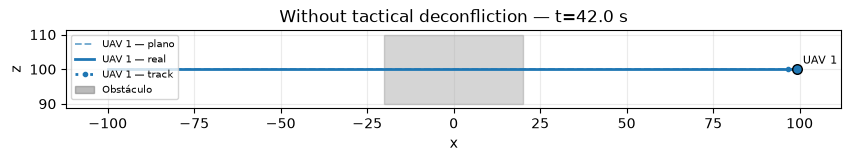

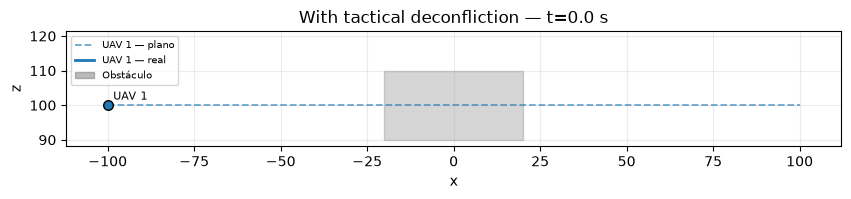

In [6]:
for case_name, dataset_path in dataset_paths.items():
    animation_path = OUTPUT_DIRECTORY / f"{case_name}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        output_path=animation_path,
        fps=6.0,
        dpi=100,
    )
    display(Image(filename=animation_path))
    print("Saved:", animation_path)

## Expected interpretation

Without TD, the UAV follows the initially approved plan through the obstacle. With TD, the short-term track predicts the violation during flight and a tactical plan update commands the UAV above the obstacle before it returns to its original destination altitude.